In [1]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

{'cells': [], 'metadata': {}, 'nbformat': 4, 'nbformat_minor': 5}

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import linregress

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from scipy.stats import linregress

from qvp.classical.grid import create_grid
from qvp.physics.distributions import perturbed_maxwellian
from qvp.classical.poisson import calculate_electric_field
from qvp.classical.solver import rk4_step
from qvp.analysis.observables import (
    total_mass,
    total_momentum,
    total_energy,
    conservation_drift,
)

In [4]:
alpha = 0.01
k = 0.5

In [5]:
L = 2 * np.pi / k

Nx = 128
Nv = 128

v_min = -6.0
v_max = 6.0

x = np.linspace(0, L, Nx, endpoint=False)
v = np.linspace(v_min, v_max, Nv)

dx = L / Nx
dv = (v_max - v_min) / (Nv - 1)

X, V = np.meshgrid(x, v, indexing="ij")

kx = 2 * np.pi * np.fft.fftfreq(Nx, d=dx)

print("Nx =", Nx)
print("Nv =", Nv)
print("L  =", L)
print("dx =", dx)
print("dv =", dv)

Nx = 128
Nv = 128
L  = 12.566370614359172
dx = 0.09817477042468103
dv = 0.09448818897637795


In [6]:
f_equilibrium = (
    1 / np.sqrt(2 * np.pi)
    * np.exp(-V**2 / 2)
)

f = f_equilibrium * (
    1 + alpha * np.cos(k * X)
)

print("Initial distribution created.")

Initial distribution created.


In [7]:
E_initial, rho_initial, phi_initial = calculate_electric_field(
    f, dv, kx
)

mass_initial = total_mass(f, dx, dv)
momentum_initial = total_momentum(f, V, dx, dv)
energy_initial = total_energy(
    f, V, E_initial, dx, dv
)

print("Initial mass     :", mass_initial)
print("Initial momentum :", momentum_initial)
print("Initial energy   :", energy_initial)

Initial mass     : 12.566370596099521
Initial momentum : 9.406885345698521e-17
Initial energy   : 6.284441592048196


In [8]:
target_k = 0.5
target_mode = np.argmin(np.abs(kx - target_k))

electric_field_mode_amplitude = []

print("Target k       :", target_k)
print("Selected k     :", kx[target_mode])
print("Mode index     :", target_mode)

Target k       : 0.5
Selected k     : 0.5
Mode index     : 1


In [9]:
mass_history = []
momentum_history = []
energy_history = []

dt = 0.01
t_final = 40.0
num_steps = int(t_final / dt)

f_current = f.copy()

times = []
electric_field_amplitude = []
electric_field_mode_amplitude = []

for step in range(num_steps):

    t = step * dt

    # Calculate electric field from current distribution
    E, rho, phi_hat = calculate_electric_field(
        f_current, dv, kx
    )

    # Store time
    times.append(t)

    # Existing maximum-field diagnostic
    electric_field_amplitude.append(
        np.max(np.abs(E))
    )
    # Conservation diagnostics
    mass_history.append(
    total_mass(f_current, dx, dv)
    )

    momentum_history.append(
    total_momentum(f_current, V, dx, dv)
    )

    energy_history.append(
    total_energy(f_current, V, E, dx, dv)
    )

    # Fourier amplitude of the k = 0.5 mode
    E_hat = np.fft.fft(E)

    mode_amplitude = (
        2.0 * np.abs(E_hat[target_mode]) / Nx
    )

    electric_field_mode_amplitude.append(
        mode_amplitude
    )

    # Advance distribution using RK4
    f_current = rk4_step(
        f_current,
        dt,
        V,
        kx,
        dv
    )

    if step % 500 == 0:
        print(
            f"Step {step}/{num_steps} | "
            f"t = {t:.2f} | "
            f"|E|max = {np.max(np.abs(E)):.6e} | "
            f"|E_k| = {mode_amplitude:.6e}"
        )

Step 0/4000 | t = 0.00 | |E|max = 2.000000e-02 | |E_k| = 2.000000e-02
Step 500/4000 | t = 5.00 | |E|max = 6.572162e-03 | |E_k| = 6.572154e-03
Step 1000/4000 | t = 10.00 | |E|max = 1.532956e-03 | |E_k| = 1.532957e-03
Step 1500/4000 | t = 15.00 | |E|max = 4.150117e-04 | |E_k| = 4.150117e-04
Step 2000/4000 | t = 20.00 | |E|max = 5.939088e-04 | |E_k| = 5.939088e-04
Step 2500/4000 | t = 25.00 | |E|max = 2.955756e-04 | |E_k| = 2.955756e-04
Step 3000/4000 | t = 30.00 | |E|max = 6.592338e-05 | |E_k| = 6.592243e-05
Step 3500/4000 | t = 35.00 | |E|max = 1.958342e-05 | |E_k| = 1.958302e-05


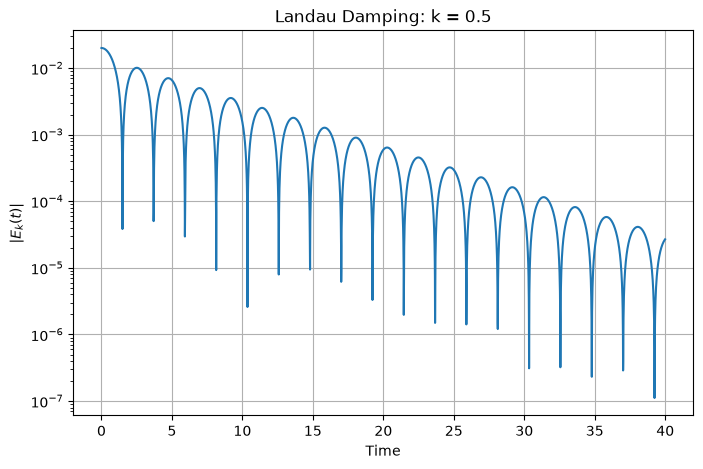

In [10]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    times,
    electric_field_mode_amplitude
)

plt.xlabel("Time")
plt.ylabel(r"$|E_k(t)|$")
plt.title("Landau Damping: k = 0.5")
plt.grid(True)

plt.show()

In [11]:
from qvp.analysis.observables import conservation_drift
mass_drift = conservation_drift(mass_history)
momentum_drift = conservation_drift(momentum_history)
energy_drift = conservation_drift(energy_history)

print("Mass drift:")
print(mass_drift)

print("\nMomentum drift:")
print(momentum_drift)

print("\nEnergy drift:")
print(energy_drift)

Mass drift:
(np.float64(-1.830713358685898e-11), np.float64(-1.4568354042129983e-12))

Momentum drift:
(np.float64(4.712963695783119e-17), nan)

Energy drift:
(np.float64(-3.361604328233625e-10), np.float64(-5.349089937421196e-11))


In [12]:
print("Mass history length     :", len(mass_history))
print("Momentum history length :", len(momentum_history))
print("Energy history length   :", len(energy_history))

Mass history length     : 4000
Momentum history length : 4000
Energy history length   : 4000


In [13]:
mass_history = np.asarray(mass_history)
momentum_history = np.asarray(momentum_history)
energy_history = np.asarray(energy_history)

mass_max_relative = (
    np.max(np.abs(mass_history - mass_history[0]))
    / np.abs(mass_history[0])
)

energy_max_relative = (
    np.max(np.abs(energy_history - energy_history[0]))
    / np.abs(energy_history[0])
)

momentum_max_absolute = np.max(
    np.abs(momentum_history - momentum_history[0])
)

print(f"Maximum relative mass deviation   : {mass_max_relative:.6e}")
print(f"Maximum relative energy deviation : {energy_max_relative:.6e}")
print(f"Maximum absolute momentum deviation: {momentum_max_absolute:.6e}")

Maximum relative mass deviation   : 2.964277e-12
Maximum relative energy deviation : 1.089358e-10
Maximum absolute momentum deviation: 5.389781e-16


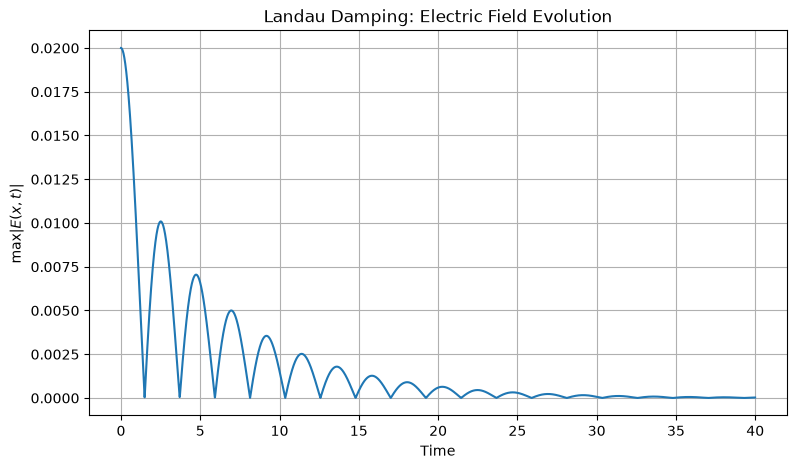

In [14]:
times = np.array(times)
electric_field_amplitude = np.array(
    electric_field_amplitude
)

plt.figure(figsize=(9, 5))

plt.plot(
    times,
    electric_field_amplitude
)

plt.xlabel("Time")
plt.ylabel(r"$\max |E(x,t)|$")
plt.title("Landau Damping: Electric Field Evolution")

plt.grid(True)
plt.show()

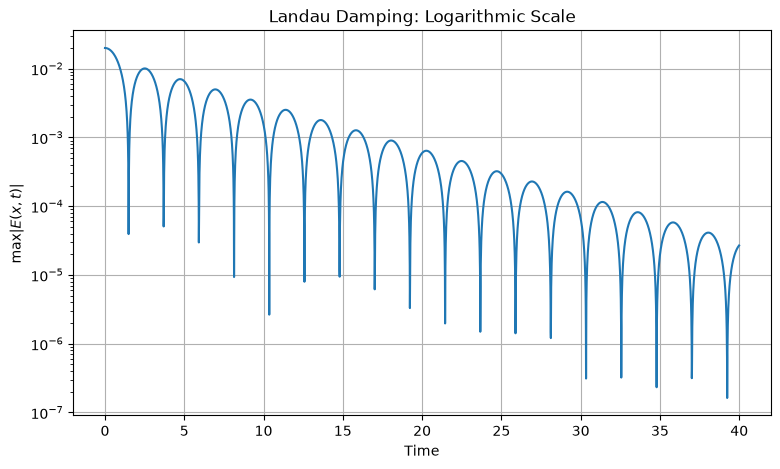

In [15]:
plt.figure(figsize=(9, 5))

plt.semilogy(
    times,
    electric_field_amplitude
)

plt.xlabel("Time")
plt.ylabel(r"$\max |E(x,t)|$")
plt.title("Landau Damping: Logarithmic Scale")

plt.grid(True)
plt.show()

In [16]:
peaks, _ = find_peaks(
    electric_field_amplitude,
    distance=20
)

peak_times = times[peaks]
peak_values = electric_field_amplitude[peaks]

print("Number of detected peaks:", len(peaks))

Number of detected peaks: 17


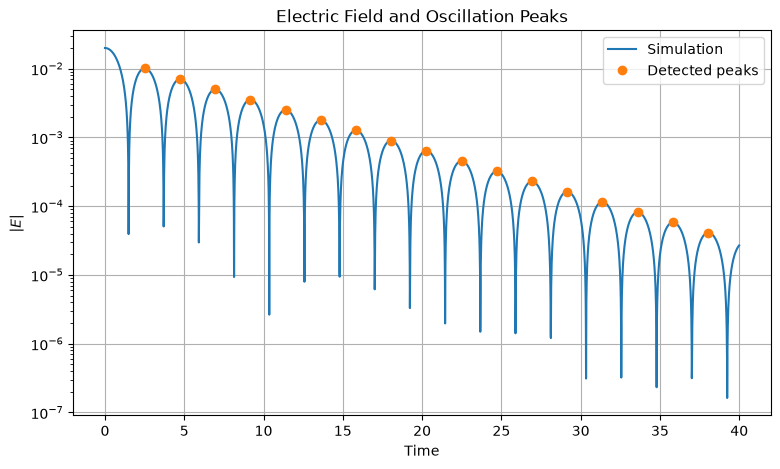

In [17]:
plt.figure(figsize=(9, 5))

plt.semilogy(
    times,
    electric_field_amplitude,
    label="Simulation"
)

plt.semilogy(
    peak_times,
    peak_values,
    "o",
    label="Detected peaks"
)

plt.xlabel("Time")
plt.ylabel(r"$|E|$")
plt.title("Electric Field and Oscillation Peaks")

plt.legend()
plt.grid(True)
plt.show()

In [18]:
log_peaks = np.log(peak_values)

fit = linregress(
    peak_times,
    log_peaks
)

gamma = -fit.slope

print(f"Estimated damping rate γ = {gamma:.6f}")
print(f"R² = {fit.rvalue**2:.6f}")

Estimated damping rate γ = 0.154515
R² = 0.999996


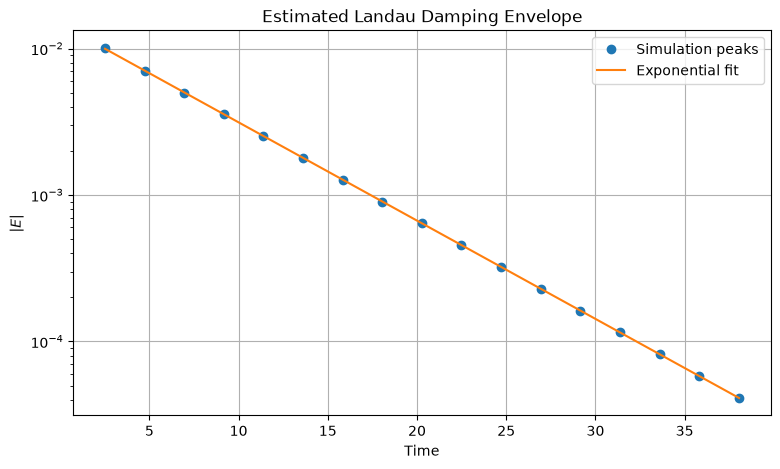

In [19]:
fitted_log = (
    fit.intercept
    + fit.slope * peak_times
)

fitted_envelope = np.exp(fitted_log)

plt.figure(figsize=(9, 5))

plt.semilogy(
    peak_times,
    peak_values,
    "o",
    label="Simulation peaks"
)

plt.semilogy(
    peak_times,
    fitted_envelope,
    label="Exponential fit"
)

plt.xlabel("Time")
plt.ylabel(r"$|E|$")
plt.title("Estimated Landau Damping Envelope")

plt.legend()
plt.grid(True)
plt.show()

In [20]:
from qvp.analysis.observables import (
    total_mass,
    total_momentum,
    total_energy,
)

In [21]:
E_initial, rho_initial, phi_initial = calculate_electric_field(
    f, dv, kx
)

mass_initial = total_mass(f, dx, dv)
momentum_initial = total_momentum(f, V, dx, dv)
energy_initial = total_energy(
    f, V, E_initial, dx, dv
)

print("Initial mass     :", mass_initial)
print("Initial momentum :", momentum_initial)
print("Initial energy   :", energy_initial)

Initial mass     : 12.566370596099521
Initial momentum : 9.406885345698521e-17
Initial energy   : 6.284441592048196
